## task-1
## Train a Linear Regression model to predict yearly amount spent by applying advanced feature selection techniques, testing interaction terms, and ensuring robustness through cross-validation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy import stats

sns.set_theme(style="whitegrid")

df = pd.read_csv("../26nov/cleaned_day8.csv")
print("Loaded Dataset Shape:", df.shape)

Loaded Dataset Shape: (5461, 101)


In [2]:
base_features = [
    "customer_age", "mrp", "discount_pct", "selling_price",
    "material_quality_score", "customer_rating", "review_word_count",
    "sentiment_score", "positive_feedback_count", "social_media_trend_score",
    "return_rate_pct", "time_on_app_mins", "time_on_website_mins",
    "dynamic_engagement_score", "log_membership_duration"
]

df["age_x_engagement"] = (df["customer_age"] * df["dynamic_engagement_score"]).round(2)
df["app_x_trend"] = (df["time_on_app_mins"] * df["social_media_trend_score"]).round(2)
df["discount_x_rating"] = (df["discount_pct"] * df["customer_rating"]).round(2)

interaction_cols = ["age_x_engagement", "app_x_trend", "discount_x_rating"]
all_features = base_features + interaction_cols

X = df[all_features]
y = df["yearly_amount_spent"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=all_features)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=all_features)

print("Training Set Shape:", X_train_scaled.shape)
print("Testing Set Shape:", X_test_scaled.shape)

Training Set Shape: (4368, 18)
Testing Set Shape: (1093, 18)


In [3]:
rfecv = RFECV(
    estimator=LinearRegression(),
    step=1,
    cv=5,
    scoring="r2"
)
rfecv.fit(X_train_scaled, y_train)

selected_features = X_train_scaled.columns[rfecv.support_].tolist()
print("Optimal Number of Features:", rfecv.n_features_)
print("Selected Features via RFECV:", selected_features)

base_cv = cross_val_score(LinearRegression(), X_train_scaled[base_features], y_train, cv=5, scoring="r2").mean()
opt_cv = cross_val_score(LinearRegression(), X_train_scaled[selected_features], y_train, cv=5, scoring="r2").mean()

print(f"5-Fold CV R2 (Base Features Only): {base_cv:.4f}")
print(f"5-Fold CV R2 (RFECV + Interactions): {opt_cv:.4f}")

lr_model = LinearRegression()
lr_model.fit(X_train_scaled[selected_features], y_train)

Optimal Number of Features: 15
Selected Features via RFECV: ['customer_age', 'mrp', 'discount_pct', 'selling_price', 'customer_rating', 'review_word_count', 'social_media_trend_score', 'return_rate_pct', 'time_on_app_mins', 'time_on_website_mins', 'dynamic_engagement_score', 'log_membership_duration', 'age_x_engagement', 'app_x_trend', 'discount_x_rating']
5-Fold CV R2 (Base Features Only): 0.9256
5-Fold CV R2 (RFECV + Interactions): 0.9284


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


## task-2
## Evaluate the model using RMSE, MAE, and R² scores by implementing k-fold cross-validation, analyzing residual plots for error patterns, and detecting potential heteroscedasticity issues.

In [4]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_r2_scores = cross_val_score(LinearRegression(), X_train_scaled[selected_features], y_train, cv=kf, scoring="r2")
cv_rmse_scores = -cross_val_score(LinearRegression(), X_train_scaled[selected_features], y_train, cv=kf, scoring="neg_root_mean_squared_error")
cv_mae_scores = -cross_val_score(LinearRegression(), X_train_scaled[selected_features], y_train, cv=kf, scoring="neg_mean_absolute_error")

y_pred = lr_model.predict(X_test_scaled[selected_features])
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
test_mae = mean_absolute_error(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)

eval_table = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "R2 Score"],
    "5_Fold_CV_Mean": [round(cv_rmse_scores.mean(), 2), round(cv_mae_scores.mean(), 2), round(cv_r2_scores.mean(), 4)],
    "5_Fold_CV_Std": [round(cv_rmse_scores.std(), 2), round(cv_mae_scores.std(), 2), round(cv_r2_scores.std(), 4)],
    "Test_Set_Score": [round(test_rmse, 2), round(test_mae, 2), round(test_r2, 4)]
})

print("Linear Regression Evaluation Summary:")
print(eval_table)

Linear Regression Evaluation Summary:
     Metric  5_Fold_CV_Mean  5_Fold_CV_Std  Test_Set_Score
0      RMSE       4041.4100       219.4900       3781.8800
1       MAE       2399.3000        52.6000       2435.9200
2  R2 Score          0.9287         0.0058          0.9343


Heteroscedasticity Spearman Correlation (|Residuals| vs Predicted): 0.2499
Heteroscedasticity P-Value: 4.9803e-17


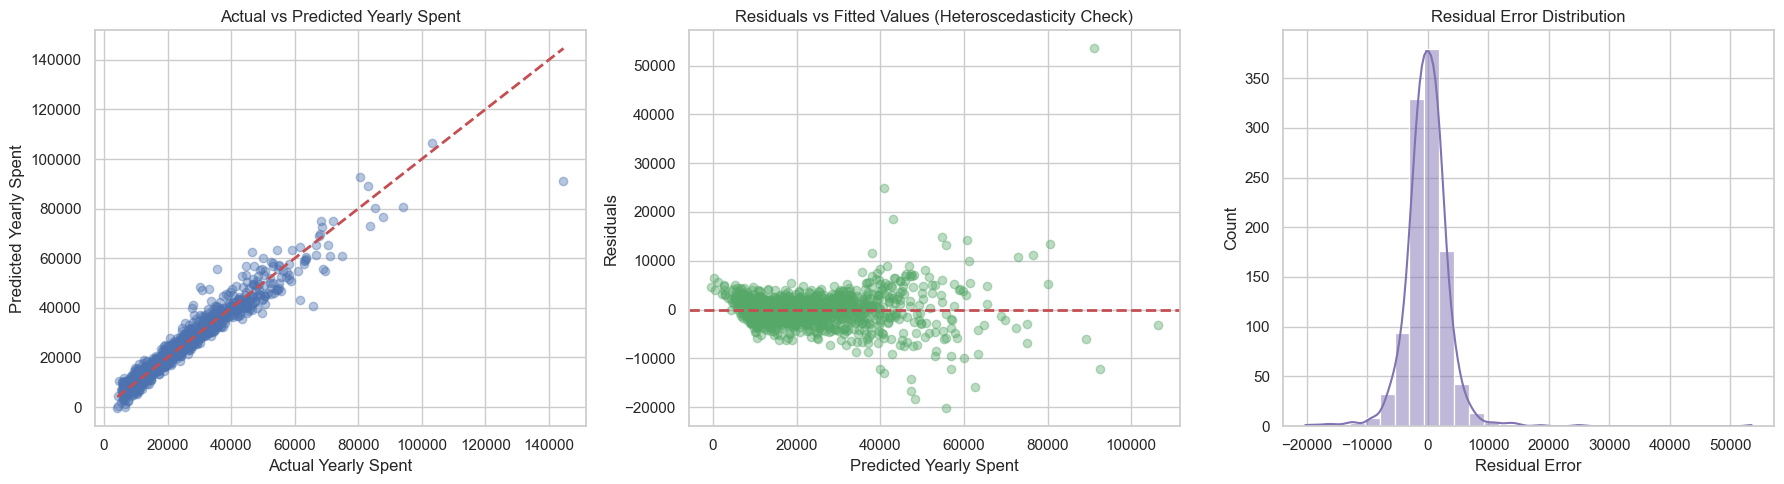

In [5]:
residuals = y_test - y_pred

het_corr, het_pvalue = stats.spearmanr(np.abs(residuals), y_pred)
print(f"Heteroscedasticity Spearman Correlation (|Residuals| vs Predicted): {het_corr:.4f}")
print(f"Heteroscedasticity P-Value: {het_pvalue:.4e}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(y_test, y_pred, alpha=0.4, color="#4C72B0")
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="#C44E52", linestyle="--", linewidth=2)
axes[0].set_title("Actual vs Predicted Yearly Spent")
axes[0].set_xlabel("Actual Yearly Spent")
axes[0].set_ylabel("Predicted Yearly Spent")

axes[1].scatter(y_pred, residuals, alpha=0.4, color="#55A868")
axes[1].axhline(0, color="#C44E52", linestyle="--", linewidth=2)
axes[1].set_title("Residuals vs Fitted Values (Heteroscedasticity Check)")
axes[1].set_xlabel("Predicted Yearly Spent")
axes[1].set_ylabel("Residuals")

sns.histplot(residuals, bins=30, kde=True, ax=axes[2], color="#8172B2")
axes[2].set_title("Residual Error Distribution")
axes[2].set_xlabel("Residual Error")

plt.tight_layout()
plt.show()

## task-3
## Train a Lasso and Ridge Regression model and compare results by systematically tuning the regularization strength, assessing feature shrinkage effects, and visualizing coefficient distributions to understand model behavior.

In [6]:
alphas_ridge = [0.1, 1.0, 10.0, 50.0, 100.0, 250.0, 500.0]
alphas_lasso = [1.0, 10.0, 25.0, 50.0, 100.0, 250.0, 500.0]

ridge_search = GridSearchCV(
    Ridge(random_state=42),
    param_grid={"alpha": alphas_ridge},
    cv=5,
    scoring="r2"
)
ridge_search.fit(X_train_scaled, y_train)

lasso_search = GridSearchCV(
    Lasso(max_iter=20000, tol=1e-3, random_state=42),
    param_grid={"alpha": alphas_lasso},
    cv=5,
    scoring="r2"
)
lasso_search.fit(X_train_scaled, y_train)

best_ridge = ridge_search.best_estimator_
best_lasso = lasso_search.best_estimator_

lr_full = LinearRegression().fit(X_train_scaled, y_train)

models_dict = {
    "Linear Regression": lr_full,
    f"Ridge (alpha={ridge_search.best_params_['alpha']})": best_ridge,
    f"Lasso (alpha={lasso_search.best_params_['alpha']})": best_lasso
}

comparison_rows = []
for name, mdl in models_dict.items():
    preds = mdl.predict(X_test_scaled)
    comparison_rows.append({
        "Model": name,
        "Test_RMSE": round(np.sqrt(mean_squared_error(y_test, preds)), 2),
        "Test_MAE": round(mean_absolute_error(y_test, preds), 2),
        "Test_R2": round(r2_score(y_test, preds), 4),
        "Zero_Coef_Count": int((np.abs(mdl.coef_) < 1e-4).sum())
    })

print("Linear vs Ridge vs Lasso Comparison:")
print(pd.DataFrame(comparison_rows))

Linear vs Ridge vs Lasso Comparison:
               Model  Test_RMSE  Test_MAE  Test_R2  Zero_Coef_Count
0  Linear Regression    3782.72   2435.02   0.9343                0
1  Ridge (alpha=1.0)    3780.04   2432.23   0.9344                0
2  Lasso (alpha=1.0)    3778.07   2431.45   0.9344                1


In [7]:
coef_df = pd.DataFrame({
    "Feature": all_features,
    "Linear_Coef": lr_full.coef_.round(2),
    "Ridge_Coef": best_ridge.coef_.round(2),
    "Lasso_Coef": best_lasso.coef_.round(2)
})

print("Feature Shrinkage Table (Model Coefficients):")
print(coef_df)

Feature Shrinkage Table (Model Coefficients):
                     Feature  Linear_Coef  Ridge_Coef  Lasso_Coef
0               customer_age       988.05      986.62      953.82
1                        mrp      3204.36     3216.67     3197.40
2               discount_pct      3937.71     3879.93     3874.00
3              selling_price     11110.08    11093.12    11114.25
4     material_quality_score       -27.05      -25.93      -24.44
5            customer_rating      3307.72     3284.49     3275.41
6          review_word_count      5761.61     1731.67      641.97
7            sentiment_score       -79.07      -75.08      -70.95
8    positive_feedback_count         8.00        6.72        5.54
9   social_media_trend_score      1185.26     1181.12     1180.78
10           return_rate_pct      -848.57     -849.02     -846.61
11          time_on_app_mins      1391.35      715.58      529.36
12      time_on_website_mins      1783.16      798.94      530.40
13  dynamic_engagement_score  

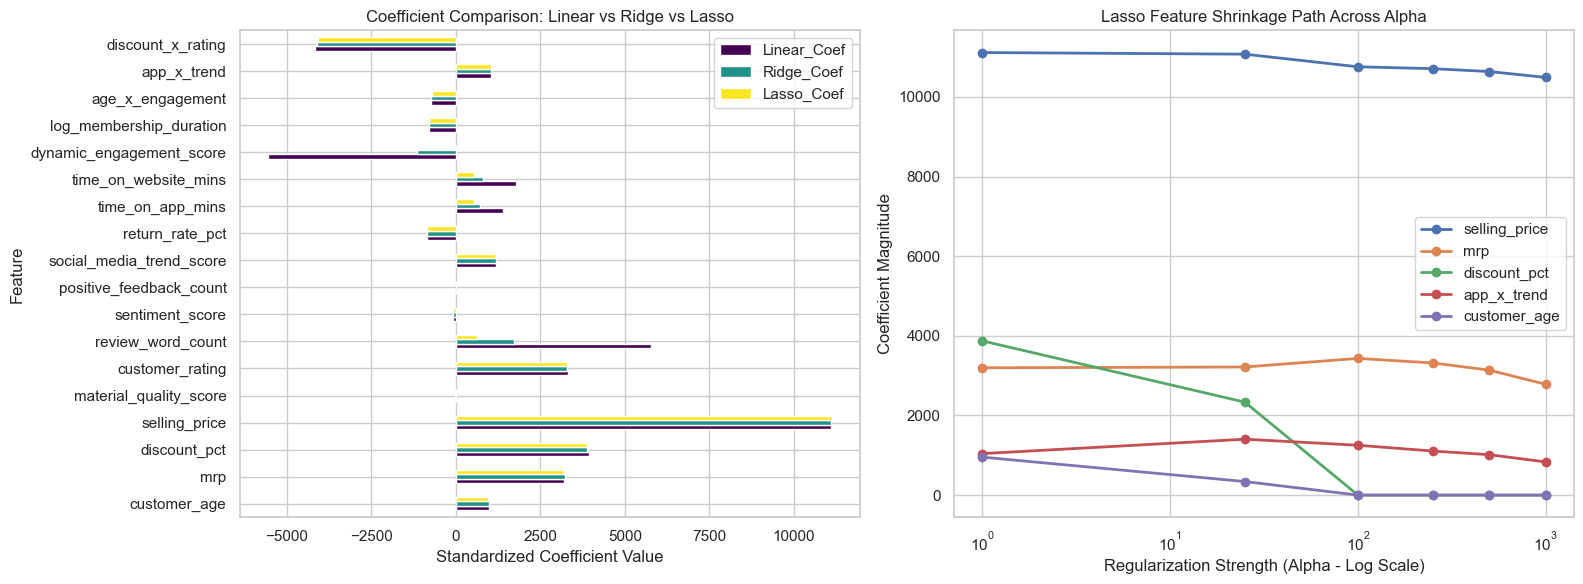

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

coef_plot_df = coef_df.set_index("Feature")
coef_plot_df.plot(kind="barh", ax=axes[0], colormap="viridis")
axes[0].set_title("Coefficient Comparison: Linear vs Ridge vs Lasso")
axes[0].set_xlabel("Standardized Coefficient Value")

shrinkage_alphas = [1.0, 25.0, 100.0, 250.0, 500.0, 1000.0]
lasso_paths = []
for a in shrinkage_alphas:
    m = Lasso(alpha=a, max_iter=20000, tol=1e-3, random_state=42).fit(X_train_scaled, y_train)
    lasso_paths.append(m.coef_)

lasso_path_df = pd.DataFrame(lasso_paths, index=shrinkage_alphas, columns=all_features)
for col in ["selling_price", "mrp", "discount_pct", "app_x_trend", "customer_age"]:
    axes[1].plot(shrinkage_alphas, lasso_path_df[col], marker="o", linewidth=2, label=col)

axes[1].set_xscale("log")
axes[1].set_title("Lasso Feature Shrinkage Path Across Alpha")
axes[1].set_xlabel("Regularization Strength (Alpha - Log Scale)")
axes[1].set_ylabel("Coefficient Magnitude")
axes[1].legend()

plt.tight_layout()
plt.show()

In [9]:
df.to_csv("cleaned_day9.csv", index=False)
print("Saved dataset to cleaned_day9.csv")

Saved dataset to cleaned_day9.csv
